# What is a Dubai home worth? — an honest price model on 1.38M official DLD sales

**Question.** Given only what is known on the day a sale is registered with the Dubai Land Department
(area, property type, off-plan vs ready, size, rooms, parking, and the *past* prices of comparable sales),
how well can we predict the registered **price per square metre** — and therefore the price?

**Data.** Dubai Land Department open data via *Dubai Real Estate Data* (dubairealestatedata.com), CC BY 4.0.
Every row is a registered sale, not an asking price.

**Rules this notebook follows**
* Every history feature for a sale on day *D* uses only sales registered **before** *D* (not the same day).
* Time-based split: train ≤ 2023, validation = 2024, test = 2025-01-01 → 2026-11-02, touched once at the end.
* Every number reported anywhere in the project is written to `results/metrics.json` by this notebook.

In [1]:
import os, sys, json, glob, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd

ON_KAGGLE = os.path.exists("/kaggle/input")
ROOT = "/kaggle/working" if ON_KAGGLE else os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
for d in ["results", "figures", "models"]:
    os.makedirs(os.path.join(ROOT, d), exist_ok=True)

from features import (FEATURES, NUMERIC, CATEGORICAL, TARGET, SQM_TO_SQFT,
                      find_data_file, load_raw, clean, build_features)
import modeling as mdl
import style
style.apply()
import matplotlib.pyplot as plt

DATA = find_data_file([os.path.join(ROOT, "data", "dld_sales_transactions.parquet")])
R = lambda *p: os.path.join(ROOT, *p)
METRICS = {}
print("data file:", DATA, "| on kaggle:", ON_KAGGLE)

data file: /home/claude/proj/data/dld_sales_transactions.parquet | on kaggle: False


## 1. Load and inspect

In [2]:
raw = load_raw(DATA)
print(raw.shape)
display(raw.head(3).T)
info = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                     "missing_pct": (raw.isna().mean() * 100).round(2),
                     "n_unique": raw.nunique()})
display(info)
dups_all_but_id = int(raw.duplicated([c for c in raw.columns if c != "transaction_id"]).sum())
print("transaction_id unique:", raw["transaction_id"].is_unique)
print("rows identical except transaction_id:", dups_all_but_id)
print(raw["quality_flags"].value_counts().sort_index())

(1382848, 20)


,0,1,2
transaction_id,1-11-1975-2,1-11-1990-1,1-11-1992-1
instance_date,1975-01-01,1990-02-12,1992-04-20
reg_type_label,Ready,Ready,Ready
area_id,232.0,268.0,270.0
area_name_en,Mirdif,Al Musalla (Dubai),Al Safaa
project_name,NaN,NaN,NaN
master_project_name,NaN,NaN,NaN
building_name,NaN,NaN,NaN
property_type_label,Villa,Land,Land
property_sub_type,NaN,NaN,NaN


,dtype,missing_pct,n_unique
transaction_id,str,0.00,1382848
instance_date,object,0.00,6167
reg_type_label,str,0.00,2
area_id,float64,0.01,244
area_name_en,str,0.01,244
project_name,str,20.59,3427
master_project_name,str,18.32,185
building_name,str,29.57,4701
property_type_label,str,0.00,4
property_sub_type,str,14.32,35


transaction_id unique: True
rows identical except transaction_id: 74762
quality_flags
0     1354155
1          10
2         737
3          38
4       27356
5         264
6         172
7         115
16          1
Name: count, dtype: int64


In [3]:
# odd values worth knowing about
d0 = pd.to_datetime(raw["instance_date"], errors="coerce")
odd = {
    "dates_before_2000": int((d0 < "2000-01-01").sum()),
    "max_date": str(d0.max().date()),
    "price_aed_max": int(raw["price_aed"].max()),
    "area_sqm_max_residential_unit": float(raw.loc[(raw.property_type_label == "Unit") & (raw.usage_label == "Residential"), "area_sqm"].max()),
    "rooms_missing_pct": float(raw["rooms_bucket"].isna().mean() * 100),
}
odd

{'dates_before_2000': 2262,
 'max_date': '2026-11-02',
 'price_aed_max': 3869204024,
 'area_sqm_max_residential_unit': 5188.54,
 'rooms_missing_pct': 20.326022816679778}

## 2. Cleaning — every decision, its reason, and the rows it removed

In [4]:
df, clean_log = clean(raw)
log_df = pd.DataFrame(clean_log)
display(log_df)
METRICS["dataset"] = {
    "rows_raw": int(len(raw)),
    "rows_clean": int(len(df)),
    "date_min_clean": str(df["date"].min().date()),
    "date_max_clean": str(df["date"].max().date()),
    "n_areas": int(df["area_id"].nunique()),
    "duplicates_all_but_id_raw": dups_all_but_id,
    "license": "CC BY 4.0",
    "source": "Dubai Land Department open data via dubairealestatedata.com",
}
METRICS["cleaning_log"] = clean_log

,step,reason,rows_before,rows_after,rows_removed
0,raw,file as downloaded,1382848,1382848,0
1,quality_flags == 0,"publisher's own checks: price floor, area rang...",1382848,1354155,28693
2,residential Unit/Villa only,Land trades on plot area and whole Buildings p...,1354155,1094417,259738
3,drop non-home sub-types,offices/shops/hotel rooms/hotel apartments reg...,1094417,1088107,6310
4,drop exact duplicates (all columns except tran...,cannot tell identical bulk sales from re-regis...,1088107,1032748,55359
5,date >= 2010-01-01,pre-2010 years are thin (<10k rows/yr before 2...,1032748,966666,66082


## 3. EDA — facts worth telling

In [5]:
df["year"] = df["date"].dt.year
yr = df.groupby("year")
by_year = pd.DataFrame({
    "transactions": yr.size(),
    "offplan_share_pct": yr.apply(lambda g: (g["reg_type_label"] == "Off-Plan").mean() * 100),
    "median_psm": yr["psm"].median(),
    "median_size_sqm": yr["area_sqm"].median(),
})
display(by_year.round(1))

y25 = df[df.year == 2025]
reg25 = y25.groupby("reg_type_label")["psm"].median()
a = (df[df.year.isin([2021, 2025])].groupby(["area_name_en", "year"])["psm"]
       .agg(["median", "size"]).unstack())
a = a[(a["size"] >= 300).all(axis=1)]
a = pd.DataFrame({"psm_2021": a[("median", 2021)], "psm_2025": a[("median", 2025)],
                  "n_2021": a[("size", 2021)], "n_2025": a[("size", 2025)]})
a["growth_pct"] = (a["psm_2025"] / a["psm_2021"] - 1) * 100
a = a.sort_values("growth_pct", ascending=False)
top_area_25 = y25["area_name_en"].value_counts()

facts = {
    "tx_2020": int(by_year.loc[2020, "transactions"]),
    "tx_2025": int(by_year.loc[2025, "transactions"]),
    "tx_multiple_2025_vs_2020": round(by_year.loc[2025, "transactions"] / by_year.loc[2020, "transactions"], 1),
    "offplan_share_2021_pct": round(by_year.loc[2021, "offplan_share_pct"], 1),
    "offplan_share_2025_pct": round(by_year.loc[2025, "offplan_share_pct"], 1),
    "median_psm_2020": int(round(by_year.loc[2020, "median_psm"])),
    "median_psm_2025": int(round(by_year.loc[2025, "median_psm"])),
    "median_psm_growth_2020_2025_pct": round((by_year.loc[2025, "median_psm"] / by_year.loc[2020, "median_psm"] - 1) * 100, 1),
    "median_size_2020_sqm": round(by_year.loc[2020, "median_size_sqm"], 1),
    "median_size_2025_sqm": round(by_year.loc[2025, "median_size_sqm"], 1),
    "median_size_2026ytd_sqm": round(by_year.loc[2026, "median_size_sqm"], 1),
    "median_size_2021_sqm": round(by_year.loc[2021, "median_size_sqm"], 1),
    "median_size_2026_is_lowest_since_2010": bool(by_year["median_size_sqm"].idxmin() == 2026),
    "offplan_psm_2025": int(round(reg25["Off-Plan"])),
    "ready_psm_2025": int(round(reg25["Ready"])),
    "offplan_premium_2025_pct": round((reg25["Off-Plan"] / reg25["Ready"] - 1) * 100, 1),
    "fastest_area_2021_2025": a.index[0],
    "fastest_area_growth_pct": round(a["growth_pct"].iloc[0], 1),
    "marina_growth_pct": round(a.loc["Marsa Dubai", "growth_pct"], 1),
    "n_areas_compared_2021_2025": int(len(a)),
    "busiest_area_2025": top_area_25.index[0],
    "busiest_area_2025_tx": int(top_area_25.iloc[0]),
    "busiest_area_2025_share_pct": round(top_area_25.iloc[0] / len(y25) * 100, 1),
    "share_2025_at_least_1m_aed_pct": round((y25["price_aed"] >= 1_000_000).mean() * 100, 1),
}
METRICS["facts"] = facts
METRICS["by_year"] = {int(k): {kk: (round(float(vv), 2)) for kk, vv in v.items()} for k, v in by_year.to_dict("index").items()}
METRICS["area_growth_2021_2025_top10"] = [
    {"area": i, "psm_2021": int(round(r.psm_2021)), "psm_2025": int(round(r.psm_2025)),
     "growth_pct": round(float(r.growth_pct), 1)}
    for i, r in a.head(10).iterrows()]
facts

,transactions,offplan_share_pct,median_psm,median_size_sqm
year,,,,
2010,24941,29.7,9444.8,94.4
2011,20115,9.1,8843.7,115.4
2012,24785,10.3,9232.2,106.0
2013,44109,17.4,10108.3,99.4
2014,39038,25.9,11042.5,90.9
2015,29502,37.2,10574.6,91.6
2016,28886,47.4,10686.7,90.5
2017,33609,54.6,10910.3,93.8
2018,23962,54.3,11217.7,82.3


{'tx_2020': 25028,
 'tx_2025': 173914,
 'tx_multiple_2025_vs_2020': np.float64(6.9),
 'offplan_share_2021_pct': np.float64(46.0),
 'offplan_share_2025_pct': np.float64(71.5),
 'median_psm_2020': 9934,
 'median_psm_2025': 18156,
 'median_psm_growth_2020_2025_pct': np.float64(82.8),
 'median_size_2020_sqm': np.float64(97.0),
 'median_size_2025_sqm': np.float64(76.5),
 'median_size_2026ytd_sqm': np.float64(72.3),
 'median_size_2021_sqm': np.float64(109.6),
 'median_size_2026_is_lowest_since_2010': True,
 'offplan_psm_2025': 19476,
 'ready_psm_2025': 14691,
 'offplan_premium_2025_pct': np.float64(32.6),
 'fastest_area_2021_2025': 'Nadd Hessa',
 'fastest_area_growth_pct': np.float64(152.5),
 'marina_growth_pct': np.float64(38.7),
 'n_areas_compared_2021_2025': 30,
 'busiest_area_2025': 'Al Barsha South Fourth',
 'busiest_area_2025_tx': 17285,
 'busiest_area_2025_share_pct': np.float64(9.9),
 'share_2025_at_least_1m_aed_pct': np.float64(71.8)}

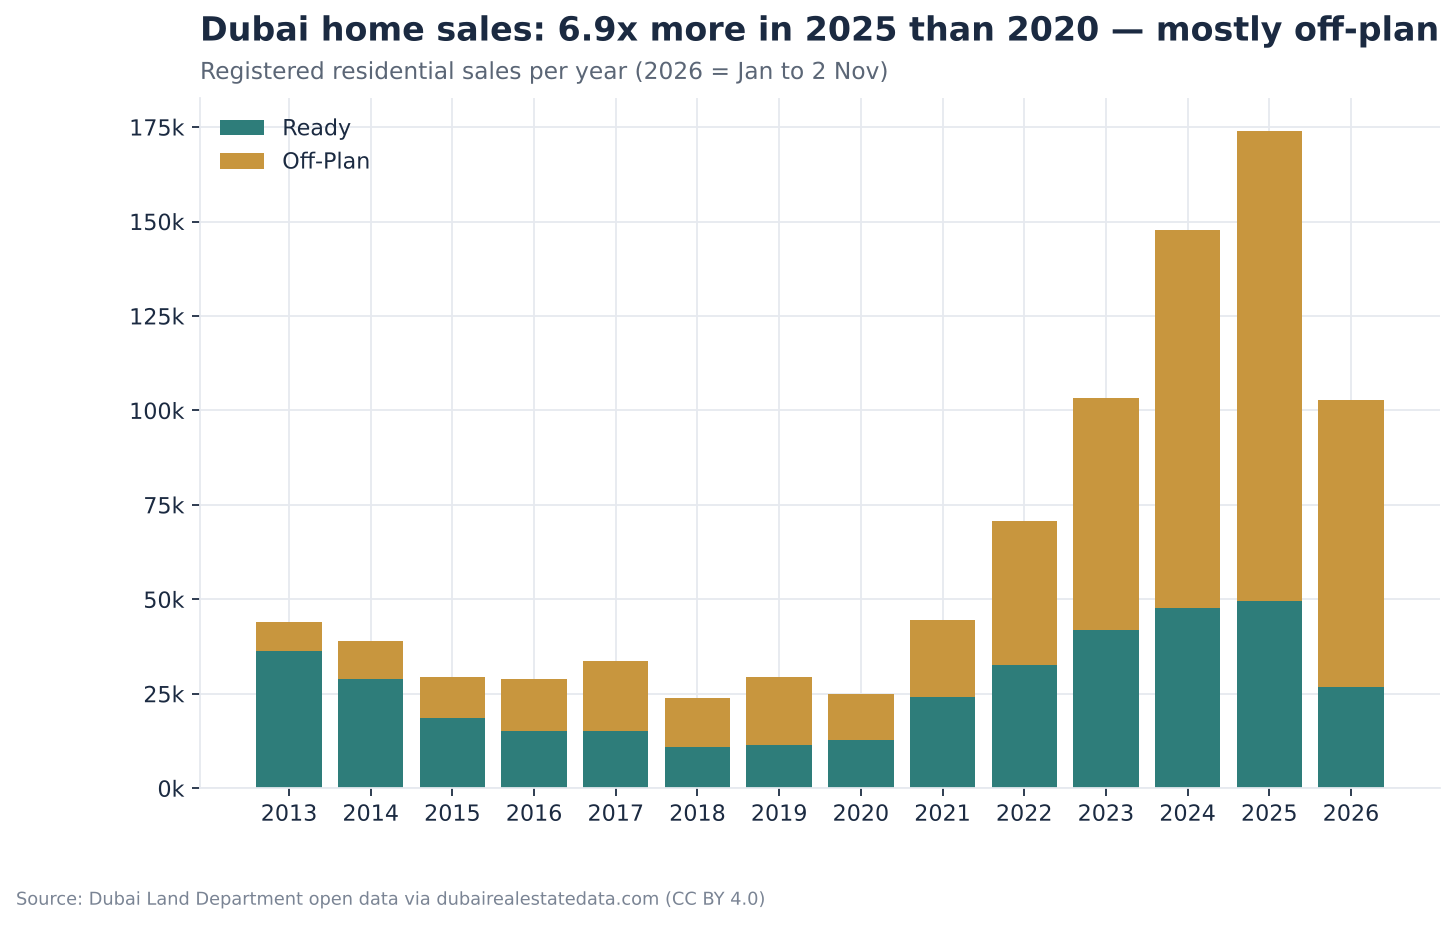

In [6]:
# Figure 1 - the boom in volume, driven by off-plan
fig, ax = plt.subplots()
p = df[df.year >= 2013].groupby(["year", "reg_type_label"]).size().unstack()[["Ready", "Off-Plan"]]
ax.bar(p.index, p["Ready"], color=style.ACCENT_2, label="Ready")
ax.bar(p.index, p["Off-Plan"], bottom=p["Ready"], color=style.ACCENT, label="Off-Plan")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
style.title(ax, f"Dubai home sales: {facts['tx_multiple_2025_vs_2020']}x more in 2025 than 2020 — mostly off-plan",
            "Registered residential sales per year (2026 = Jan to 2 Nov)")
ax.legend(loc="upper left"); ax.set_xticks(p.index)
style.source(fig); style.save(fig, R("figures", "01_volume_by_year.png"));
from IPython.display import Image; Image(R("figures", "01_volume_by_year.png"), width=760)

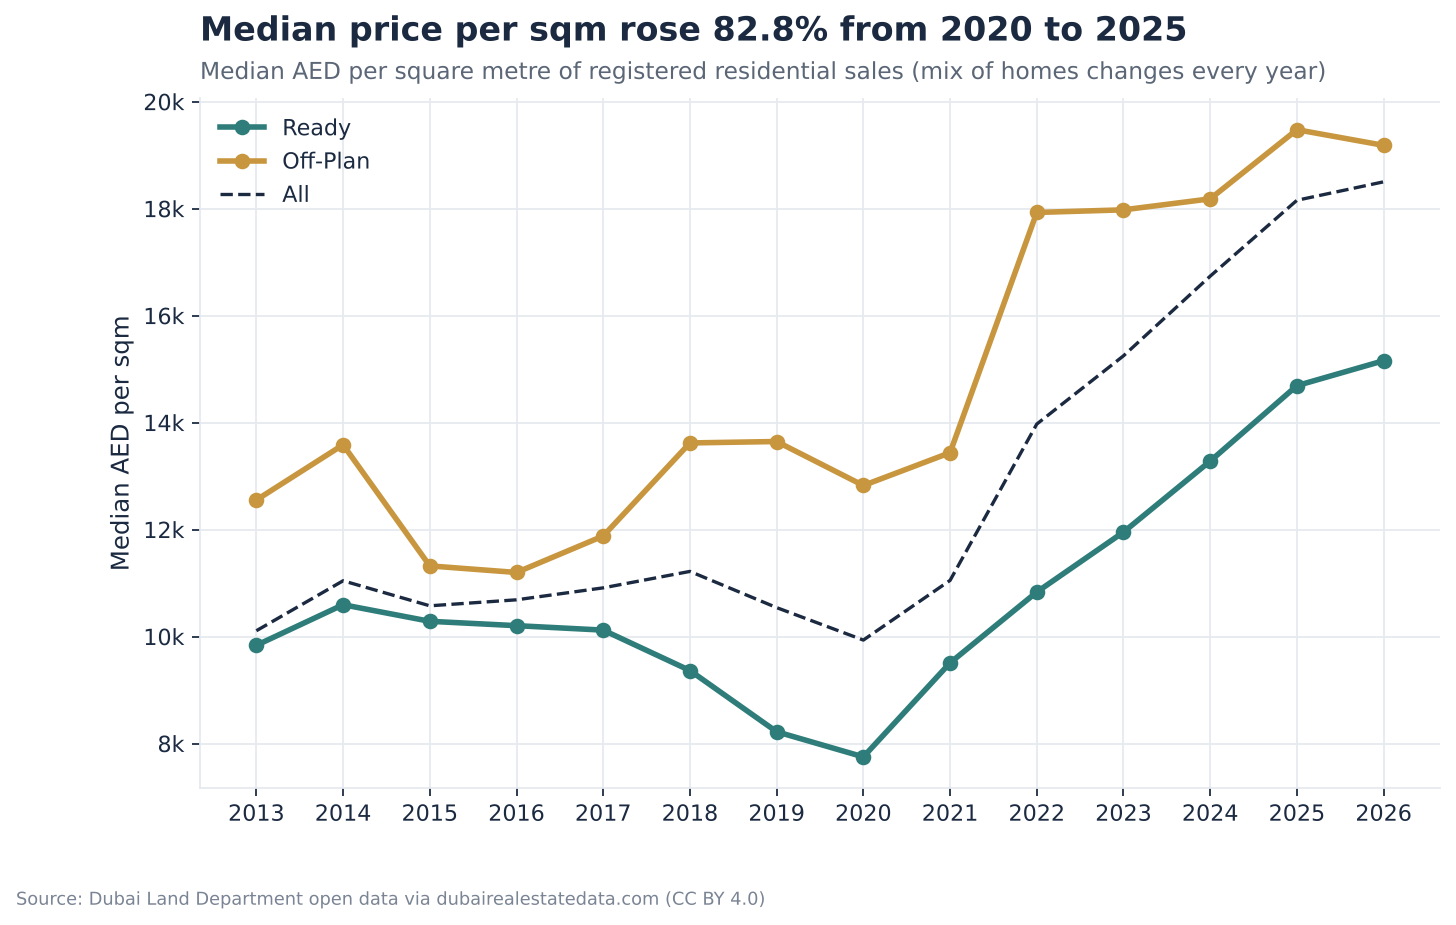

In [7]:
# Figure 2 - price per sqm by year
fig, ax = plt.subplots()
q = df[df.year >= 2013].groupby(["year", "reg_type_label"])["psm"].median().unstack()
for k in ["Ready", "Off-Plan"]:
    ax.plot(q.index, q[k], marker="o", lw=2.5, color=style.SERIES[k], label=k)
allm = df[df.year >= 2013].groupby("year")["psm"].median()
ax.plot(allm.index, allm, ls="--", color=style.INK, lw=1.5, label="All")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set_ylabel("Median AED per sqm"); ax.set_xticks(q.index)
style.title(ax, f"Median price per sqm rose {facts['median_psm_growth_2020_2025_pct']}% from 2020 to 2025",
            "Median AED per square metre of registered residential sales (mix of homes changes every year)")
ax.legend(loc="upper left")
style.source(fig); style.save(fig, R("figures", "02_psm_by_year.png")); Image(R("figures", "02_psm_by_year.png"), width=760)

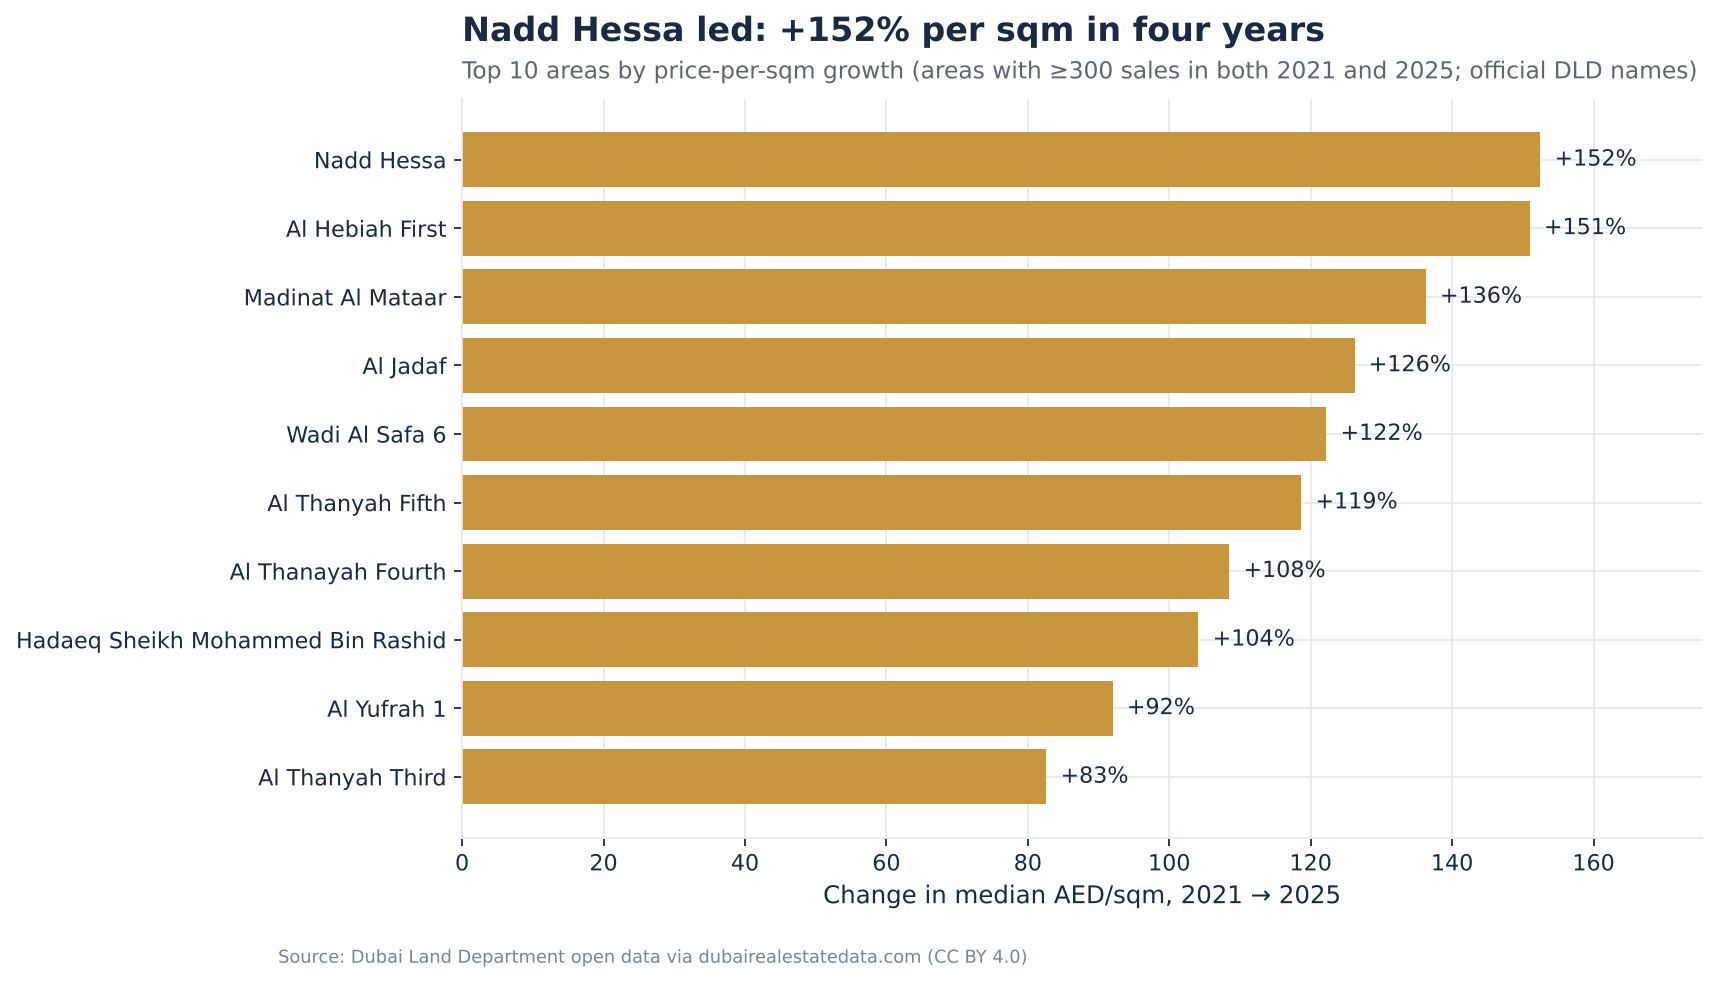

In [8]:
# Figure 3 - which areas ran fastest
top = a.head(10).iloc[::-1]
g = top["growth_pct"]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, g, color=style.ACCENT)
for y_, v in enumerate(g):
    ax.text(v + 2, y_, f"+{v:.0f}%", va="center", fontsize=10)
ax.set_xlabel("Change in median AED/sqm, 2021 → 2025")
ax.set_xlim(0, g.max() * 1.15)
style.title(ax, f"{facts['fastest_area_2021_2025']} led: +{facts['fastest_area_growth_pct']:.0f}% per sqm in four years",
            "Top 10 areas by price-per-sqm growth (areas with ≥300 sales in both 2021 and 2025; official DLD names)")
style.source(fig); style.save(fig, R("figures", "03_area_growth.png")); Image(R("figures", "03_area_growth.png"), width=760)

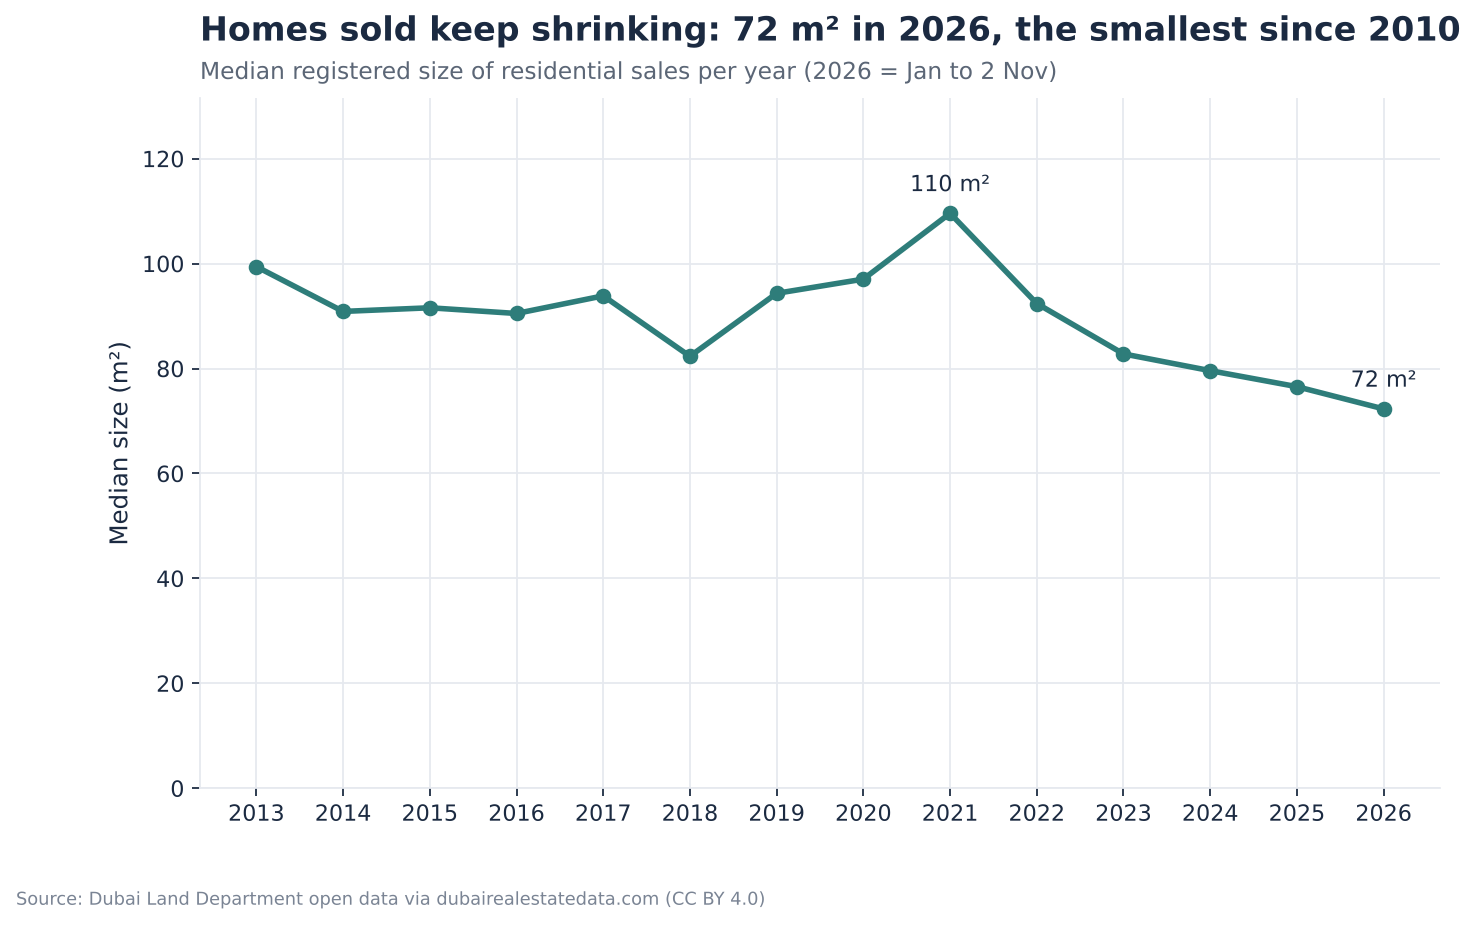

In [9]:
# Figure 4 - homes are getting smaller
fig, ax = plt.subplots()
s = by_year.loc[2013:, "median_size_sqm"]
ax.plot(s.index, s.values, marker="o", lw=2.5, color=style.ACCENT_2)
for x_ in [2021, 2026]:
    ax.annotate(f"{s.loc[x_]:.0f} m²", (x_, s.loc[x_]), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_ylabel("Median size (m²)"); ax.set_xticks(s.index); ax.set_ylim(0, s.max() * 1.2)
assert facts["median_size_2026_is_lowest_since_2010"]
style.title(ax, f"Homes sold keep shrinking: {facts['median_size_2026ytd_sqm']:.0f} m² in 2026, the smallest since 2010",
            f"Median registered size of residential sales per year (2026 = Jan to 2 Nov)")
style.source(fig); style.save(fig, R("figures", "04_size_by_year.png")); Image(R("figures", "04_size_by_year.png"), width=760)

## 4. Features (leakage-safe) and the time split

History features (all computed from sales **strictly before** the registration day):
area / area×type×off-plan / area×rooms means of log(AED per sqm) over the past 365 or 90 days,
project means (365 days and all history), building means (all history), market means (30 days),
counts of those comparables, and project age. Plus the row's own facts: size, rooms, parking,
off-plan vs ready, Unit vs Villa, procedure group, area code, month.

In [10]:
feat = build_features(df)
train, val, test = mdl.time_split(feat)
METRICS["splits"] = {
    "train": {"from": str(train.date.min().date()), "to": str(train.date.max().date()), "n": int(len(train))},
    "validation": {"from": str(val.date.min().date()), "to": str(val.date.max().date()), "n": int(len(val))},
    "test": {"from": str(test.date.min().date()), "to": str(test.date.max().date()), "n": int(len(test))},
    "n_features": len(FEATURES),
}
METRICS["splits"]

{'train': {'from': '2013-01-02', 'to': '2023-12-29', 'n': 472273},
 'validation': {'from': '2024-01-01', 'to': '2024-12-31', 'n': 147747},
 'test': {'from': '2025-01-01', 'to': '2026-11-02', 'n': 276805},
 'n_features': 23}

In [11]:
# In-notebook leakage check (the full version lives in tests/test_no_leakage.py):
# recompute a few features by brute force using only earlier days and compare.
rng = np.random.RandomState(0)
sample = feat[feat.date >= "2018-01-01"].sample(40, random_state=0)
for _, row in sample.iterrows():
    past = feat[(feat.area_id == row.area_id) & (feat.date < row.date) &
                (feat.date >= row.date - pd.Timedelta(days=365))]
    exp = past[TARGET].mean() if len(past) else np.nan
    assert (np.isnan(exp) and np.isnan(row.area_mean_365)) or np.isclose(exp, row.area_mean_365), row.transaction_id
    mk = feat[(feat.date < row.date) & (feat.date >= row.date - pd.Timedelta(days=30))][TARGET].mean()
    assert np.isclose(mk, row.mkt_mean_30)
assert not {TARGET, "psm", "price_aed", "price_psf"} & set(FEATURES)
print("leakage check passed on", len(sample), "random rows")

leakage check passed on 40 random rows


## 5. Baselines and models (selection on the 2024 validation year only)

* **Market baseline** — last 30 days' average for off-plan/ready.
* **Comps rule (one strong feature)** — average of the same area + type + off-plan/ready over the past 365 days.
* **Building rule** — past sales in the same building, else same project, else the comps rule. A tough, hand-made benchmark.
* Ridge (linear), Random Forest (300k-row subsample), XGBoost, LightGBM.
  (PerpetualBooster was also tried, but its scores changed between two identical runs, so it was left out to keep every number reproducible.)

Target: log(AED per sqm). Main metric: **median absolute % error on the price (MdAPE)**, plus the share of
sales predicted within ±10% and ±20% (the usual way automated valuation models are judged).

In [12]:
yv, yte, ytr = val[TARGET], test[TARGET], train[TARGET]
val_preds, test_preds, models, timings = {}, {}, {}, {}
for name, fn in [("Market baseline", mdl.baseline_market), ("Comps rule (1 feature)", mdl.baseline_comps),
                 ("Building rule", mdl.baseline_building)]:
    val_preds[name], test_preds[name] = fn(val), fn(test)

Xtr, Xva, Xte = mdl.X_tree(train), mdl.X_tree(val), mdl.X_tree(test)
Ctr, Cva, Cte = mdl.X_codes(train, train), mdl.X_codes(val, train), mdl.X_codes(test, train)

m, timings["Ridge (linear)"] = mdl.timed(mdl.make_linear().fit, train[FEATURES], ytr)
models["Ridge (linear)"] = m; val_preds["Ridge (linear)"] = m.predict(val[FEATURES]); test_preds["Ridge (linear)"] = m.predict(test[FEATURES])
m, timings["Random Forest"] = mdl.timed(mdl.fit_rf, Ctr, ytr)
models["Random Forest"] = m; val_preds["Random Forest"] = m.predict(Cva); test_preds["Random Forest"] = m.predict(Cte)
m, timings["XGBoost"] = mdl.timed(mdl.fit_xgb, Xtr, ytr, Xva, yv)
models["XGBoost"] = m; val_preds["XGBoost"] = m.predict(Xva); test_preds["XGBoost"] = m.predict(Xte)
m, timings["LightGBM"] = mdl.timed(mdl.fit_lgbm, Xtr, ytr, Xva, yv)
models["LightGBM"] = m; val_preds["LightGBM"] = m.predict(Xva); test_preds["LightGBM"] = m.predict(Xte)

val_table = pd.DataFrame({k: mdl.price_metrics(yv, p) for k, p in val_preds.items()}).T.sort_values("mdape_pct")
METRICS["validation"] = {k: {kk: round(vv, 3) if isinstance(vv, float) else vv for kk, vv in v.items()} for k, v in val_table.to_dict("index").items()}
display(val_table.round(2))
print("fit seconds:", timings)

,mdape_pct,mape_pct,within_10pct,within_20pct,r2_log_psm,mae_log,n
LightGBM,6.95,9.51,64.98,89.79,0.90,0.09,147747.0
XGBoost,7.13,9.71,63.78,89.40,0.90,0.10,147747.0
Random Forest,7.21,10.05,63.38,88.28,0.89,0.10,147747.0
Building rule,8.74,12.44,54.70,79.51,0.81,0.13,147747.0
Ridge (linear),10.32,13.11,48.74,78.73,0.84,0.13,147747.0
Comps rule (1 feature),12.37,16.36,41.99,69.98,0.72,0.17,147747.0
Market baseline,28.37,33.65,16.90,34.14,0.13,0.32,147747.0


fit seconds: {'Ridge (linear)': 11.8, 'Random Forest': 166.0, 'XGBoost': 45.6, 'LightGBM': 21.3}


## 6. Tune the best model family with Optuna (validation year only)

In [13]:
ml_names = [k for k in val_table.index if k not in ("Market baseline", "Comps rule (1 feature)", "Building rule")]
best_family = val_table.loc[ml_names, "mdape_pct"].idxmin()
print("best family on validation:", best_family)
assert best_family in ("LightGBM", "XGBoost"), "tuning implemented for LightGBM (and XGBoost via the same pattern)"
N_TRIALS = 25
study = mdl.tune_lgbm(Xtr, ytr, Xva, yv, n_trials=N_TRIALS)
best = dict(study.best_params); best_iter = study.best_trial.user_attrs["best_iter"]
print(best, "| best iteration:", best_iter, "| val MdAPE:", round(study.best_value, 3))

tuned_tr = mdl.fit_lgbm(Xtr, ytr, Xva, yv, learning_rate=0.08, **best)
val_preds["LightGBM (tuned)"] = tuned_tr.predict(Xva)
METRICS["tuning"] = {"family": "LightGBM", "n_trials": N_TRIALS, "learning_rate": 0.08,
                     "best_params": {k: (round(v, 6) if isinstance(v, float) else v) for k, v in best.items()},
                     "best_iteration": int(best_iter),
                     "val_mdape_untuned": round(METRICS["validation"]["LightGBM"]["mdape_pct"], 3),
                     "val_mdape_tuned": round(float(study.best_value), 3)}
METRICS["validation"]["LightGBM (tuned)"] = {kk: round(vv, 3) if isinstance(vv, float) else vv
                                              for kk, vv in mdl.price_metrics(yv, val_preds["LightGBM (tuned)"]).items()}
METRICS["tuning"]

best family on validation: LightGBM


{'num_leaves': 54, 'min_child_samples': 91, 'colsample_bytree': 0.6902575558328141, 'subsample': 0.8588394269448006, 'reg_lambda': 0.4636650275987655, 'min_split_gain': 0.04667159430924534} | best iteration: 447 | val MdAPE: 6.883


{'family': 'LightGBM',
 'n_trials': 25,
 'learning_rate': 0.08,
 'best_params': {'num_leaves': 54,
  'min_child_samples': 91,
  'colsample_bytree': 0.690258,
  'subsample': 0.858839,
  'reg_lambda': 0.463665,
  'min_split_gain': 0.046672},
 'best_iteration': 447,
 'val_mdape_untuned': 6.947,
 'val_mdape_tuned': 6.883}

## 7. Final model → the untouched test period (2025-01-01 → 2026-11-02)

The tuned LightGBM is refit once on train + validation (≤ 2024) with the number of trees found on validation,
then scored on the test period. Every other model is also scored on test **for reference only** —
the choice was already made on validation.

In [14]:
import lightgbm as lgb
trval = pd.concat([train, val])
final = lgb.LGBMRegressor(**mdl.lgbm_params(learning_rate=0.08, n_estimators=best_iter, **best))
final.fit(mdl.X_tree(trval), trval[TARGET])
test_preds["LightGBM (tuned, final)"] = final.predict(Xte)
test_table = pd.DataFrame({k: mdl.price_metrics(yte, p) for k, p in test_preds.items()}).T.sort_values("mdape_pct")
METRICS["test"] = {k: {kk: round(vv, 3) if isinstance(vv, float) else vv for kk, vv in v.items()} for k, v in test_table.to_dict("index").items()}
display(test_table.round(2))

fin, bld, cmp_ = (METRICS["test"]["LightGBM (tuned, final)"], METRICS["test"]["Building rule"],
                  METRICS["test"]["Comps rule (1 feature)"])
METRICS["headline"] = {
    "final_model": "LightGBM (tuned, final)",
    "test_mdape_pct": fin["mdape_pct"], "test_within_10pct": fin["within_10pct"], "test_within_20pct": fin["within_20pct"],
    "test_r2_log_psm": fin["r2_log_psm"],
    "building_rule_test_mdape_pct": bld["mdape_pct"], "comps_rule_test_mdape_pct": cmp_["mdape_pct"],
    "error_reduction_vs_building_rule_pct": round((1 - fin["mdape_pct"] / bld["mdape_pct"]) * 100, 1),
    "error_reduction_vs_comps_rule_pct": round((1 - fin["mdape_pct"] / cmp_["mdape_pct"]) * 100, 1),
    "beats_best_baseline_on_test": bool(fin["mdape_pct"] < min(bld["mdape_pct"], cmp_["mdape_pct"])),
    "val_mdape_tuned_pct": METRICS["tuning"]["val_mdape_tuned"],
}
METRICS["headline"]

,mdape_pct,mape_pct,within_10pct,within_20pct,r2_log_psm,mae_log,n
"LightGBM (tuned, final)",6.80,11.02,65.34,88.24,0.85,0.10,276805.0
LightGBM,7.50,11.67,61.47,86.78,0.84,0.10,276805.0
Random Forest,7.63,12.44,60.49,84.82,0.82,0.11,276805.0
Building rule,8.30,12.82,56.82,81.43,0.77,0.13,276805.0
XGBoost,8.44,13.70,56.67,82.08,0.62,0.14,276805.0
Ridge (linear),12.40,19.65,41.95,69.93,-0.85,0.26,276805.0
Comps rule (1 feature),12.46,16.98,41.32,71.26,0.67,0.16,276805.0
Market baseline,25.47,30.54,21.61,40.22,0.12,0.29,276805.0


{'final_model': 'LightGBM (tuned, final)',
 'test_mdape_pct': 6.804,
 'test_within_10pct': 65.343,
 'test_within_20pct': 88.24,
 'test_r2_log_psm': 0.847,
 'building_rule_test_mdape_pct': 8.304,
 'comps_rule_test_mdape_pct': 12.456,
 'error_reduction_vs_building_rule_pct': 18.1,
 'error_reduction_vs_comps_rule_pct': 45.4,
 'beats_best_baseline_on_test': True,
 'val_mdape_tuned_pct': 6.883}

### 7b. What if the model is retrained every month? (walk-forward)
The frozen model above never sees 2025-26 prices. In production you would retrain as new sales are registered.
Here, for each test month, the same tuned LightGBM is refit on **all sales before that month** and scores only that month.

In [15]:
wf_pred = pd.Series(np.nan, index=test.index)
months = test.date.dt.to_period("M")
for per in sorted(months.unique()):
    start = per.start_time
    hist = feat[(feat.date >= "2013-01-01") & (feat.date < start)]
    mm = lgb.LGBMRegressor(**mdl.lgbm_params(learning_rate=0.08, n_estimators=best_iter, **best))
    mm.fit(mdl.X_tree(hist), hist[TARGET])
    idx = months[months == per].index
    wf_pred.loc[idx] = mm.predict(mdl.X_tree(test.loc[idx]))
test_preds["LightGBM retrained monthly (walk-forward)"] = wf_pred.to_numpy()
METRICS["walk_forward"] = {kk: round(vv, 3) if isinstance(vv, float) else vv
                           for kk, vv in mdl.price_metrics(yte, wf_pred.to_numpy()).items()}
METRICS["walk_forward"]

{'mdape_pct': 6.034,
 'mape_pct': 9.775,
 'within_10pct': 70.055,
 'within_20pct': 90.993,
 'r2_log_psm': 0.868,
 'mae_log': 0.088,
 'n': 276805}

In [16]:
# Does it hold up over time and across segments?
te = test.assign(pred=test_preds["LightGBM (tuned, final)"], bld=test_preds["Building rule"],
                 wf=test_preds["LightGBM retrained monthly (walk-forward)"])
te["ape_wf"] = np.abs(np.exp(te.wf) / te.psm - 1) * 100
te["ape"] = np.abs(np.exp(te.pred) / te.psm - 1) * 100
te["ape_bld"] = np.abs(np.exp(te.bld) / te.psm - 1) * 100
te["ym"] = te.date.dt.to_period("M").astype(str)
by_month = te.groupby("ym").agg(n=("ape", "size"), mdape_model=("ape", "median"), mdape_building_rule=("ape_bld", "median"),
                                mdape_walk_forward=("ape_wf", "median"))
te["has_bldg_history"] = np.where(te.bldg_n_all >= 3, "≥3 past sales in building", "new / unknown building")
seg = {}
for col in ["reg_type_label", "prop_type", "has_bldg_history"]:
    g = te.groupby(col, observed=True).agg(n=("ape", "size"), mdape_model=("ape", "median"), mdape_building_rule=("ape_bld", "median"))
    seg[col] = {str(k): {kk: round(float(vv), 2) for kk, vv in v.items()} for k, v in g.to_dict("index").items()}
METRICS["test_by_month"] = {k: {kk: round(float(vv), 2) for kk, vv in v.items()} for k, v in by_month.to_dict("index").items()}
METRICS["test_by_segment"] = seg
first3, last3 = by_month.mdape_model.iloc[:3].mean(), by_month.mdape_model.iloc[-3:].mean()
better = by_month.mdape_model < by_month.mdape_building_rule
worse_months = by_month.index[~better].tolist()
wf_better = by_month.mdape_walk_forward < by_month.mdape_building_rule
METRICS["drift"] = {"mdape_first3_months_avg": round(float(first3), 2), "mdape_last3_months_avg": round(float(last3), 2),
                    "first_month": by_month.index[0], "last_month": by_month.index[-1], "n_months": int(len(by_month)),
                    "frozen_months_better_than_building_rule": int(better.sum()),
                    "frozen_first_month_worse_than_rule": worse_months[0] if worse_months else None,
                    "walk_forward_months_better_than_building_rule": int(wf_better.sum()),
                    "walk_forward_last3_months_avg": round(float(by_month.mdape_walk_forward.iloc[-3:].mean()), 2),
                    "last_month_is_partial_days": int(test.date.max().day)}
display(by_month.round(2)); seg

,n,mdape_model,mdape_building_rule,mdape_walk_forward
ym,,,,
2025-01,10567,6.22,9.37,6.22
2025-02,12486,6.37,9.74,6.28
2025-03,12185,6.47,9.34,6.14
2025-04,13746,6.53,9.10,6.14
2025-05,14154,6.50,9.10,6.16
2025-06,12951,6.22,8.32,5.73
2025-07,16286,6.32,7.82,5.74
2025-08,15510,6.40,8.17,5.97
2025-09,17295,6.20,8.53,5.53


{'reg_type_label': {'Off-Plan': {'n': 200500.0,
   'mdape_model': 6.07,
   'mdape_building_rule': 6.71},
  'Ready': {'n': 76305.0, 'mdape_model': 9.43, 'mdape_building_rule': 15.82}},
 'prop_type': {'Unit': {'n': 259256.0,
   'mdape_model': 6.73,
   'mdape_building_rule': 8.03},
  'Villa': {'n': 17549.0, 'mdape_model': 8.11, 'mdape_building_rule': 13.13}},
 'has_bldg_history': {'new / unknown building': {'n': 102973.0,
   'mdape_model': 8.03,
   'mdape_building_rule': 8.32},
  '≥3 past sales in building': {'n': 173832.0,
   'mdape_model': 6.22,
   'mdape_building_rule': 8.29}}}

## 8. How sure is it? Prediction intervals (regression → no probability calibration)

This is regression, so instead of a calibration curve we check whether stated uncertainty is honest:
an 80% interval built from the 2024 validation residuals (split conformal), then measured on 2025-26.

In [17]:
half = mdl.split_conformal(yv - val_preds["LightGBM (tuned)"], alpha=0.2)
inside = np.abs(yte - test_preds["LightGBM (tuned, final)"]) <= half
by_m_cov = pd.Series(inside.values, index=te.ym).groupby(level=0).mean() * 100
METRICS["interval"] = {"nominal_coverage_pct": 80.0, "half_width_log": round(half, 4),
                       "relative_band_pct": [round((np.exp(-half) - 1) * 100, 1), round((np.exp(half) - 1) * 100, 1)],
                       "test_coverage_pct": round(float(inside.mean() * 100), 2),
                       "test_coverage_min_month_pct": round(float(by_m_cov.min()), 2)}
METRICS["interval"]

{'nominal_coverage_pct': 80.0,
 'half_width_log': 0.1449,
 'relative_band_pct': [np.float64(-13.5), np.float64(15.6)],
 'test_coverage_pct': 79.2,
 'test_coverage_min_month_pct': 68.54}

## 9. Explanation — SHAP

In [18]:
import shap
shap_sample = test.sample(4000, random_state=mdl.SEED)
explainer = shap.TreeExplainer(final)
sv = explainer.shap_values(mdl.X_tree(shap_sample))
imp = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
METRICS["shap_mean_abs_top10"] = {k: round(float(v), 4) for k, v in imp.head(10).items()}
imp.head(10)

proj_mean_365      0.221643
seg_mean_365       0.068353
log_area_sqm       0.067172
rooms_mean_365     0.065804
bldg_mean_all      0.051393
rooms              0.039539
area_id_cat        0.023977
area_mean_90       0.018448
mkt_reg_mean_30    0.015832
proj_mean_all      0.009173
dtype: float64

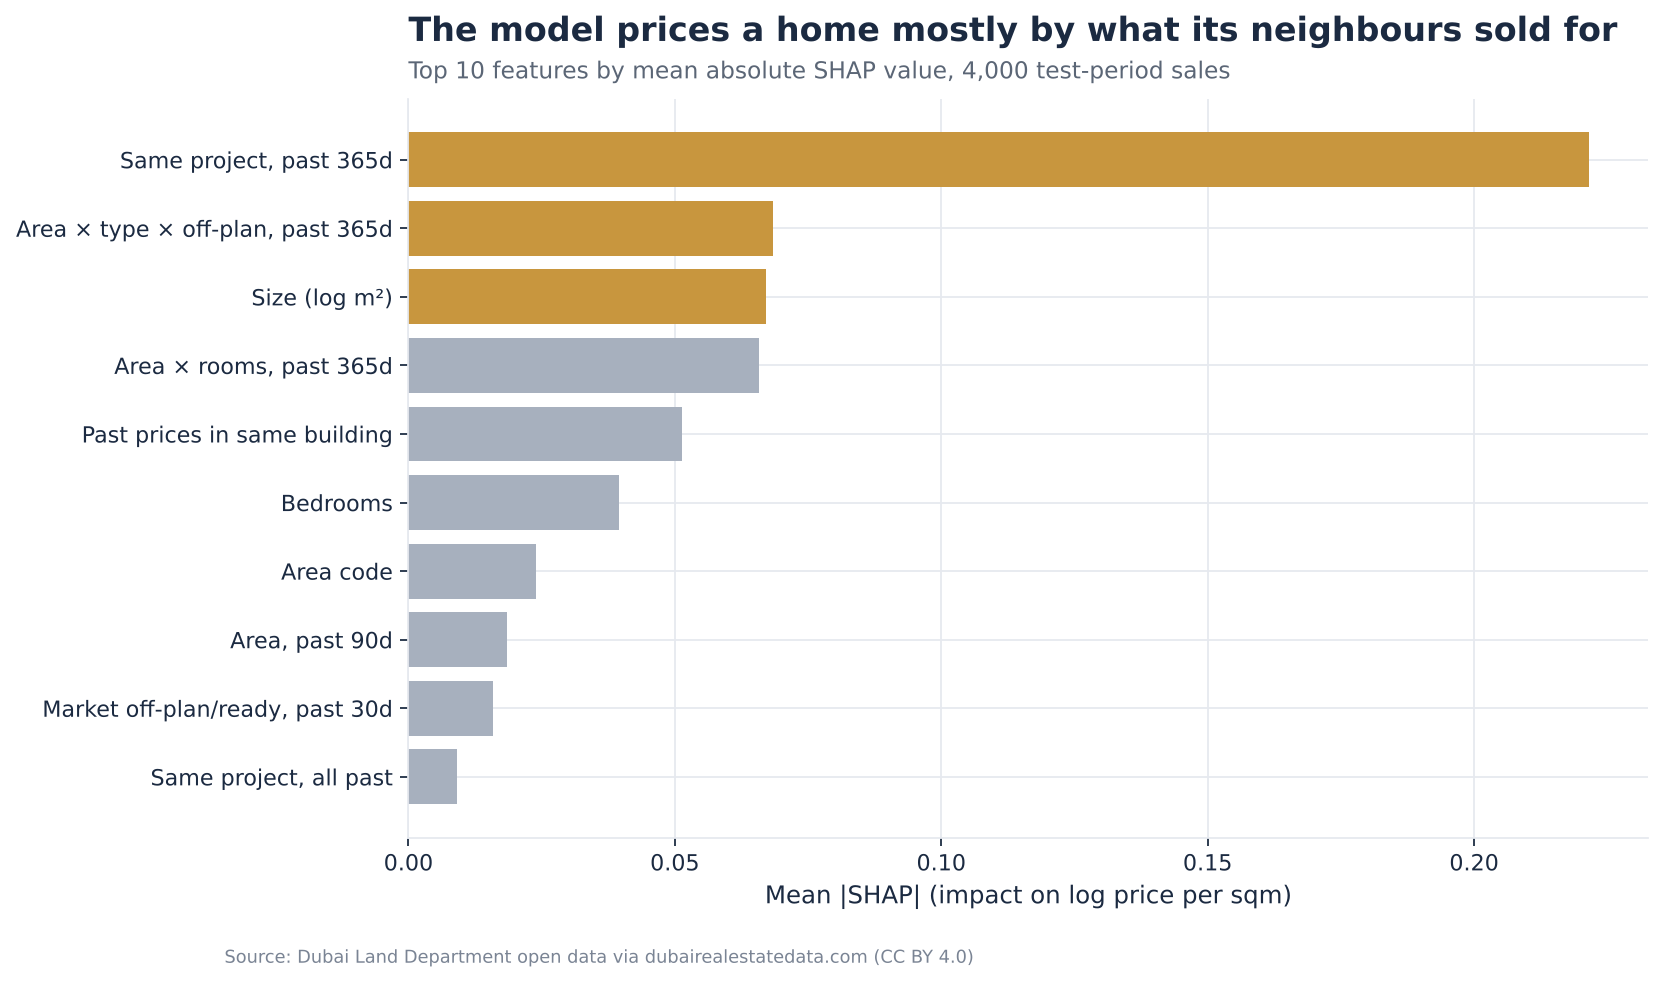

In [19]:
FEATURE_LABELS = {
    "bldg_mean_all": "Past prices in same building", "proj_mean_365": "Same project, past 365d",
    "proj_mean_all": "Same project, all past", "seg_mean_365": "Area × type × off-plan, past 365d",
    "area_mean_365": "Area, past 365d", "area_mean_90": "Area, past 90d", "rooms_mean_365": "Area × rooms, past 365d",
    "log_area_sqm": "Size (log m²)", "rooms": "Bedrooms", "has_parking": "Parking included",
    "mkt_mean_30": "Whole market, past 30d", "mkt_reg_mean_30": "Market off-plan/ready, past 30d",
    "proj_age_days": "Project age (days)", "reg_type": "Off-plan vs ready", "prop_type": "Unit vs villa",
    "procedure_group": "DLD procedure", "area_id_cat": "Area code", "month": "Month",
    "area_n_365": "# area sales, past 365d", "seg_n_365": "# segment sales, past 365d",
    "proj_n_365": "# project sales, past 365d", "proj_n_all": "# project sales, all past", "bldg_n_all": "# building sales, all past",
}
fig, ax = plt.subplots(figsize=(10, 6))
t10 = imp.head(10).iloc[::-1]
ax.barh([FEATURE_LABELS.get(k, k) for k in t10.index], t10.values, color=[style.ACCENT if i >= 7 else style.MUTED for i in range(10)])
ax.set_xlabel("Mean |SHAP| (impact on log price per sqm)")
style.title(ax, "The model prices a home mostly by what its neighbours sold for",
            "Top 10 features by mean absolute SHAP value, 4,000 test-period sales")
style.source(fig); style.save(fig, R("figures", "08_shap_importance.png")); Image(R("figures", "08_shap_importance.png"), width=760)

## 10. Case studies — real test-period sales the model got right and wrong

In [20]:
te["pred_price"] = np.exp(te.pred) * te.area_sqm
te["signed_err_pct"] = (te.pred_price / te.price_aed - 1) * 100
cand_hit = te[(te.bldg_n_all >= 3) & (te.ape < 1)].sort_values("transaction_id")
hit = cand_hit.iloc[len(cand_hit) // 2]
over = te[te.signed_err_pct > 0].sort_values("signed_err_pct")
over = over.iloc[int(len(over) * 0.99)]          # 99th percentile over-estimate, not the single worst row
under = te[te.signed_err_pct < 0].sort_values("signed_err_pct", ascending=False)
under = under.iloc[int(len(under) * 0.99)]       # 99th percentile under-estimate
cases = []
for label, r in [("hit", hit), ("over_estimate_p99", over), ("under_estimate_p99", under)]:
    s = explainer.shap_values(mdl.X_tree(te.loc[[r.name]]))[0]
    top = pd.Series(s, index=FEATURES).abs().sort_values(ascending=False).head(3).index
    xr = mdl.X_tree(te.loc[[r.name]]).iloc[0]
    cases.append({"case": label, "date": str(r.date.date()), "area": r.area_name_en,
                  "project": None if pd.isna(r.project_name) else r.project_name,
                  "type": r.property_type_label, "reg_type": r.reg_type_label,
                  "rooms": None if pd.isna(r.rooms_bucket) else int(r.rooms_bucket),
                  "size_sqm": round(float(r.area_sqm), 1), "actual_aed": int(r.price_aed),
                  "predicted_aed": int(round(r.pred_price, -3)), "error_pct": round(float(r.signed_err_pct), 1),
                  "past_sales_in_building": int(r.bldg_n_all), "procedure": r.procedure_name_en,
                  "top_shap_features": [FEATURE_LABELS.get(k, k) + (" (no data)" if pd.isna(xr[k]) else "") for k in top]})
METRICS["case_studies"] = cases
pd.DataFrame(cases).T

,0,1,2
case,hit,over_estimate_p99,under_estimate_p99
date,2025-07-21,2026-02-26,2025-12-17
area,Wadi Al Safa 5,Al Hebiah First,Palm Deira
project,VERDANIA 2,NaN,LIA
type,Unit,Unit,Unit
reg_type,Off-Plan,Ready,Off-Plan
rooms,1,3,2
size_sqm,70.0,201.5,136.0
actual_aed,1049155,1735000,5065000
predicted_aed,1057000,2848000,3428000


## 11. Result figures

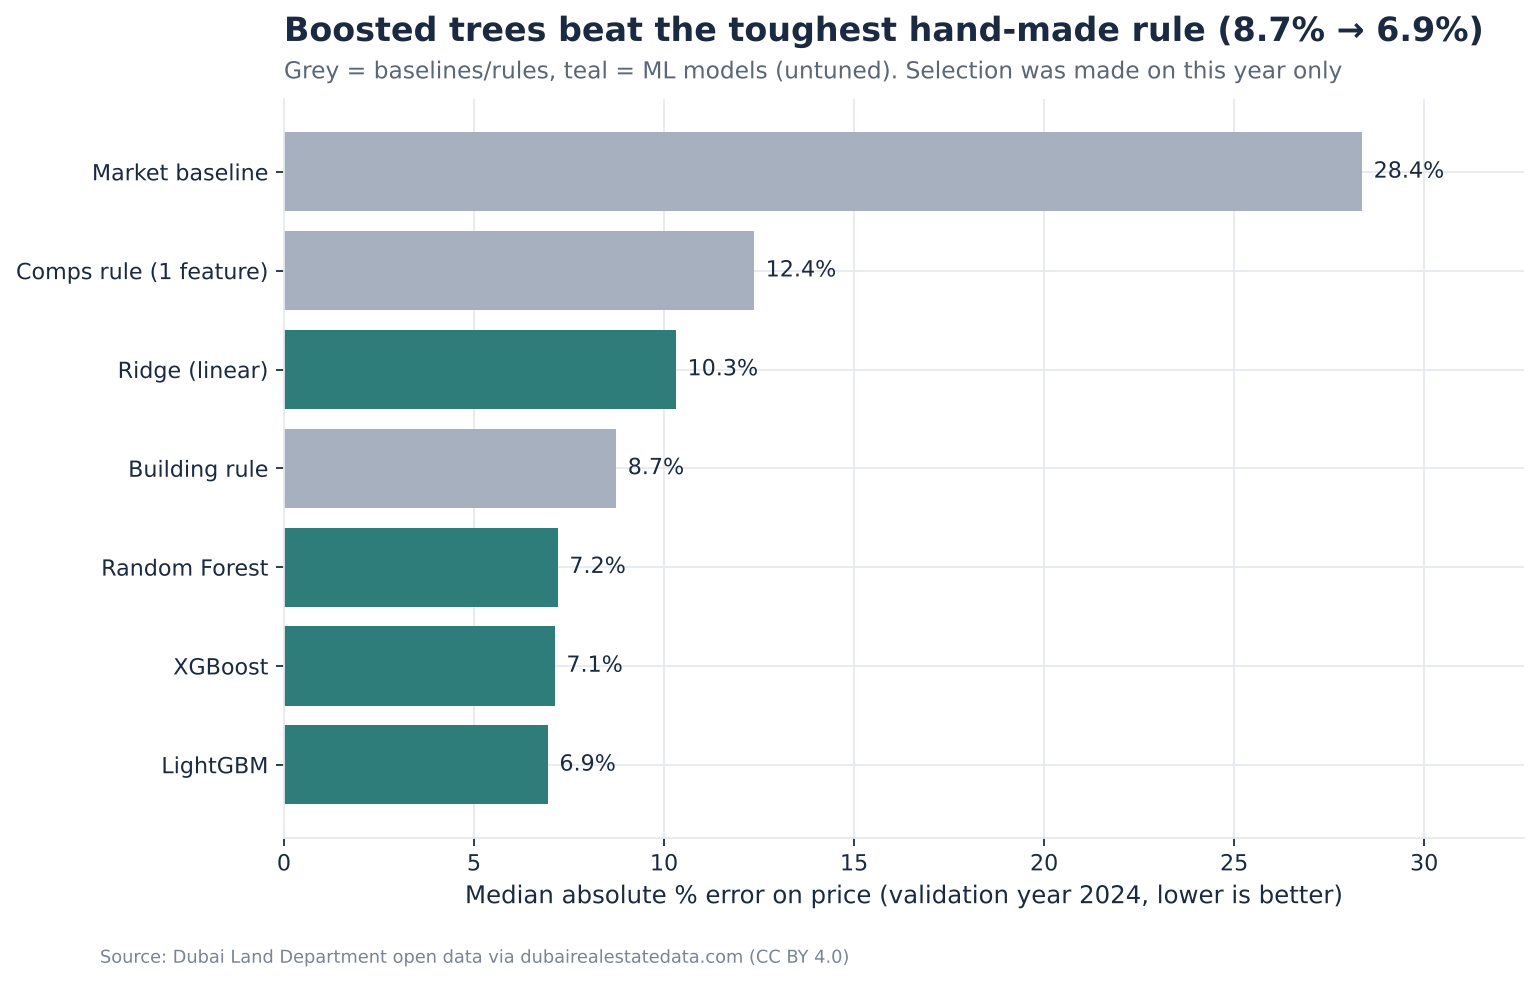

In [21]:
# Figure 5 - model comparison on validation + test
order = ["Market baseline", "Comps rule (1 feature)", "Ridge (linear)", "Building rule", "PerpetualBooster",
         "Random Forest", "XGBoost", "LightGBM"]
order = [o for o in order if o in METRICS["validation"]]
vals = [METRICS["validation"][o]["mdape_pct"] for o in order]
fig, ax = plt.subplots(figsize=(10, 6))
cols = [style.MUTED if ("rule" in o or "baseline" in o) else style.ACCENT_2 for o in order]
ax.barh(order[::-1], vals[::-1], color=cols[::-1])
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_xlabel("Median absolute % error on price (validation year 2024, lower is better)")
ax.set_xlim(0, max(vals) * 1.15)
style.title(ax, f"Boosted trees beat the toughest hand-made rule ({METRICS['validation']['Building rule']['mdape_pct']:.1f}% → {METRICS['validation']['LightGBM']['mdape_pct']:.1f}%)",
            "Grey = baselines/rules, teal = ML models (untuned). Selection was made on this year only")
style.source(fig); style.save(fig, R("figures", "05_model_comparison.png")); Image(R("figures", "05_model_comparison.png"), width=760)

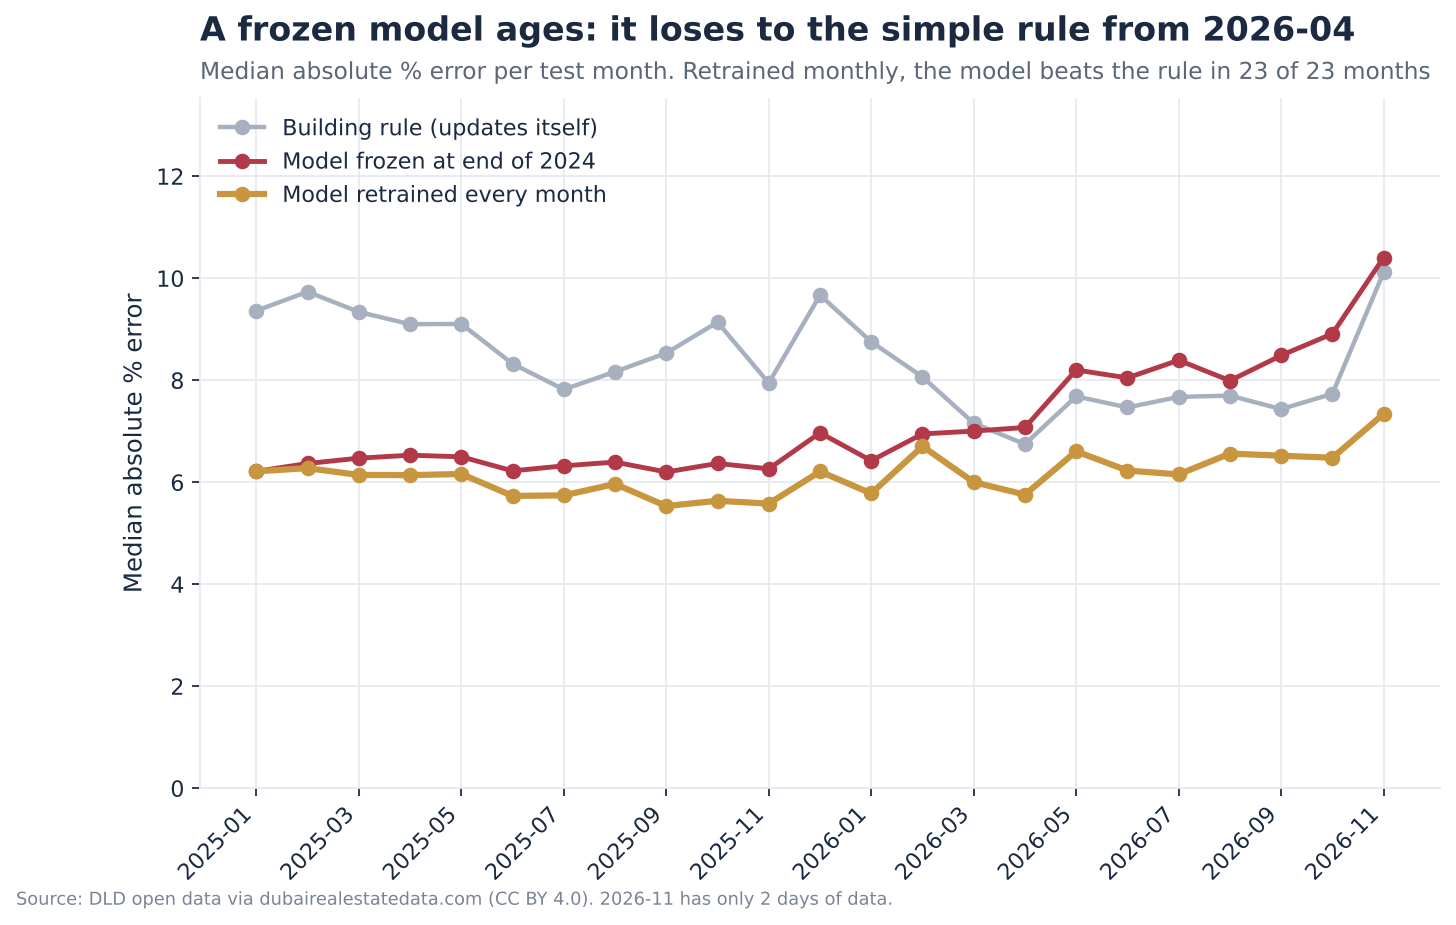

In [22]:
# Figure 6 - error over the test period: frozen vs retrained vs building rule
dr = METRICS["drift"]
fig, ax = plt.subplots()
x = np.arange(len(by_month))
ax.plot(x, by_month.mdape_building_rule, marker="o", color=style.MUTED, lw=2, label="Building rule (updates itself)")
ax.plot(x, by_month.mdape_model, marker="o", color=style.BAD, lw=2.2, label="Model frozen at end of 2024")
ax.plot(x, by_month.mdape_walk_forward, marker="o", color=style.ACCENT, lw=2.8, label="Model retrained every month")
ax.set_xticks(x[::2]); ax.set_xticklabels(by_month.index[::2], rotation=45, ha="right")
ax.set_ylabel("Median absolute % error"); ax.set_ylim(0, by_month[["mdape_model", "mdape_building_rule", "mdape_walk_forward"]].max().max() * 1.3)
ax.legend(loc="upper left")
style.title(ax, f"A frozen model ages: it loses to the simple rule from {dr['frozen_first_month_worse_than_rule']}",
            f"Median absolute % error per test month. Retrained monthly, the model beats the rule in {dr['walk_forward_months_better_than_building_rule']} of {dr['n_months']} months")
style.source(fig, f"Source: DLD open data via dubairealestatedata.com (CC BY 4.0). {dr['last_month']} has only {dr['last_month_is_partial_days']} days of data.")
style.save(fig, R("figures", "06_test_error_by_month.png")); Image(R("figures", "06_test_error_by_month.png"), width=760)

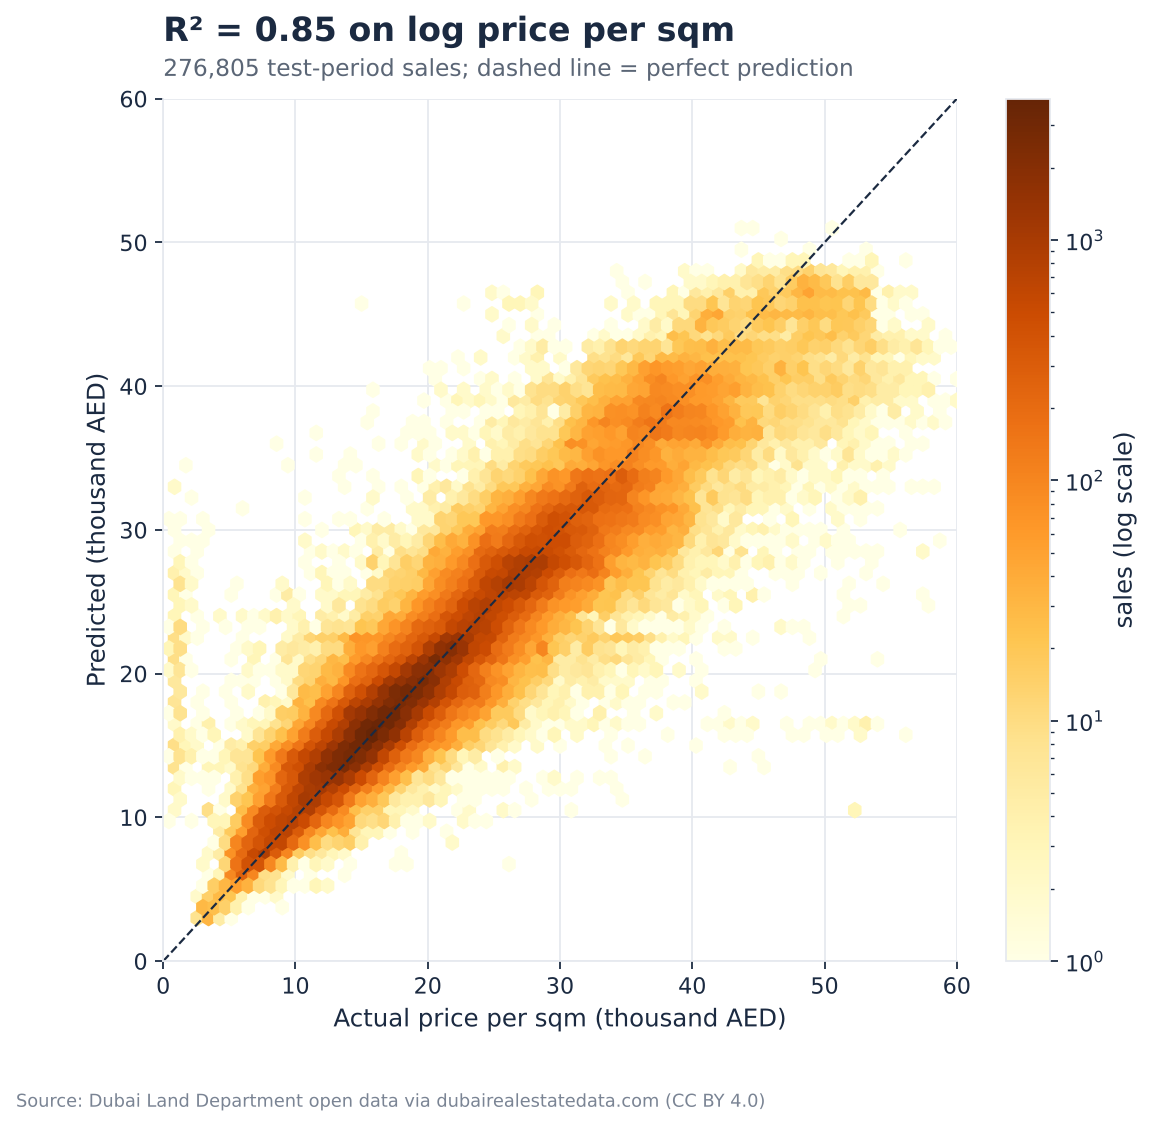

In [23]:
# Figure 7 - predicted vs actual price per sqm (test)
fig, ax = plt.subplots(figsize=(8, 7))
hb = ax.hexbin(np.exp(yte) / 1000, np.exp(test_preds["LightGBM (tuned, final)"]) / 1000, gridsize=70, bins="log",
               cmap="YlOrBr", mincnt=1, extent=(0, 60, 0, 60))
ax.plot([0, 60], [0, 60], color=style.INK, lw=1, ls="--")
ax.set_xlim(0, 60); ax.set_ylim(0, 60)
ax.set_xlabel("Actual price per sqm (thousand AED)"); ax.set_ylabel("Predicted (thousand AED)")
fig.colorbar(hb, ax=ax, label="sales (log scale)")
style.title(ax, f"R² = {METRICS['headline']['test_r2_log_psm']:.2f} on log price per sqm",
            f"{METRICS['splits']['test']['n']:,} test-period sales; dashed line = perfect prediction")
style.source(fig); style.save(fig, R("figures", "07_pred_vs_actual.png")); Image(R("figures", "07_pred_vs_actual.png"), width=640)

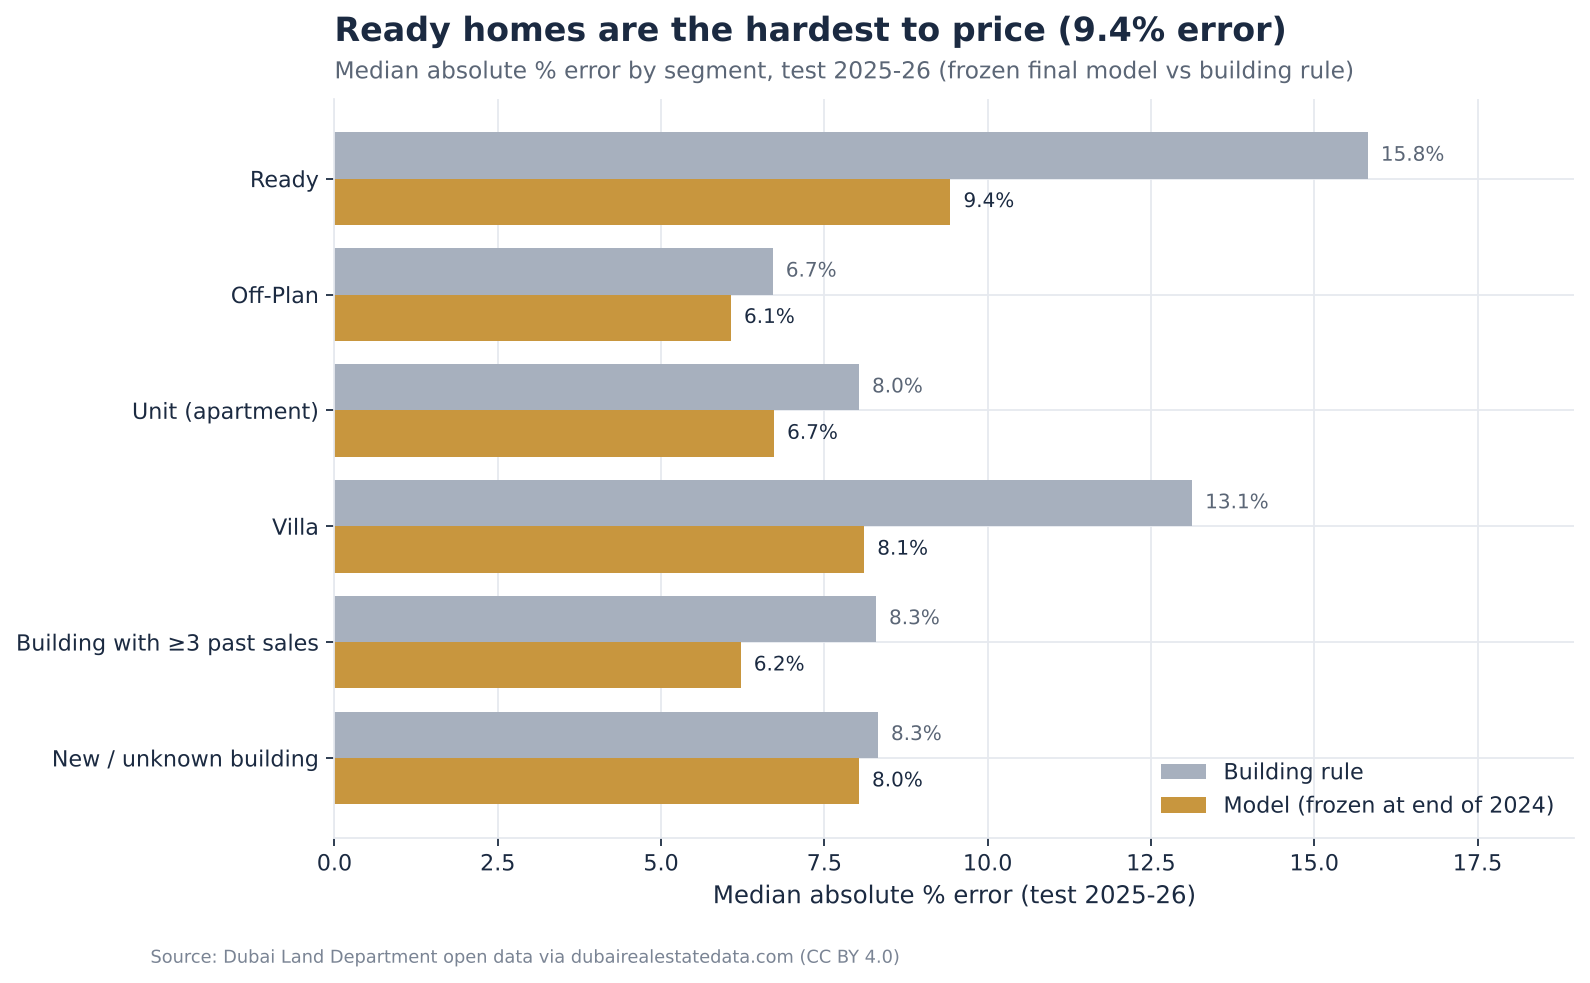

In [24]:
# Figure 9 - where it struggles
s = METRICS["test_by_segment"]
rows = [("Ready", s["reg_type_label"]["Ready"]), ("Off-Plan", s["reg_type_label"]["Off-Plan"]),
        ("Unit (apartment)", s["prop_type"]["Unit"]), ("Villa", s["prop_type"]["Villa"]),
        ("Building with ≥3 past sales", s["has_bldg_history"]["≥3 past sales in building"]),
        ("New / unknown building", s["has_bldg_history"]["new / unknown building"])]
fig, ax = plt.subplots(figsize=(10, 6))
labels = [r[0] for r in rows][::-1]; mv = [r[1]["mdape_model"] for r in rows][::-1]; bv = [r[1]["mdape_building_rule"] for r in rows][::-1]
yy = np.arange(len(rows))
ax.barh(yy + 0.2, bv, height=0.4, color=style.MUTED, label="Building rule")
ax.barh(yy - 0.2, mv, height=0.4, color=style.ACCENT, label="Model (frozen at end of 2024)")
for i in range(len(rows)):
    ax.text(mv[i] + 0.2, i - 0.2, f"{mv[i]:.1f}%", va="center", fontsize=9)
    ax.text(bv[i] + 0.2, i + 0.2, f"{bv[i]:.1f}%", va="center", fontsize=9, color="#5B6676")
ax.set_yticks(yy); ax.set_yticklabels(labels); ax.legend(loc="lower right")
ax.set_xlabel("Median absolute % error (test 2025-26)"); ax.set_xlim(0, max(bv + mv) * 1.2)
worst = max(rows, key=lambda r: r[1]["mdape_model"])
style.title(ax, f"{worst[0]} homes are the hardest to price ({worst[1]['mdape_model']:.1f}% error)",
            "Median absolute % error by segment, test 2025-26 (frozen final model vs building rule)")
style.source(fig); style.save(fig, R("figures", "09_error_by_segment.png")); Image(R("figures", "09_error_by_segment.png"), width=760)

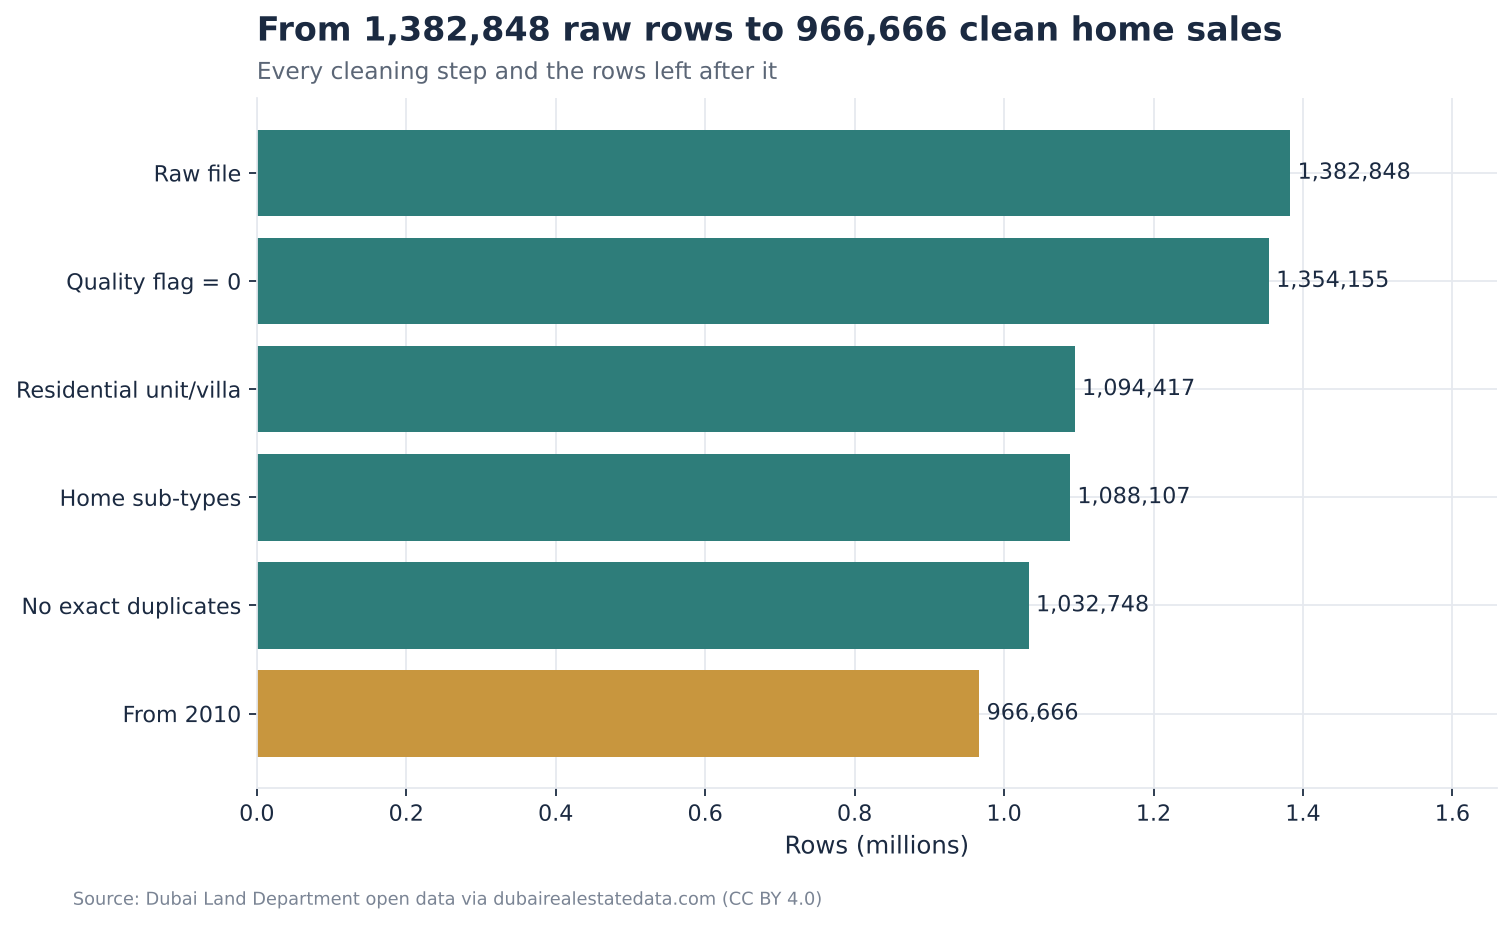

In [25]:
# Figure 10 - cleaning funnel
fig, ax = plt.subplots(figsize=(10, 5.6))
lg = pd.DataFrame(clean_log)
names = ["Raw file", "Quality flag = 0", "Residential unit/villa", "Home sub-types", "No exact duplicates", "From 2010"]
ax.barh(names[::-1], lg["rows_after"][::-1] / 1e6, color=[style.ACCENT] + [style.ACCENT_2] * (len(lg) - 1))
for i, v in enumerate(lg["rows_after"][::-1]):
    ax.text(v / 1e6 + 0.01, i, f"{v:,}", va="center", fontsize=10)
ax.set_xlabel("Rows (millions)"); ax.set_xlim(0, lg["rows_after"].max() / 1e6 * 1.2)
style.title(ax, f"From {METRICS['dataset']['rows_raw']:,} raw rows to {METRICS['dataset']['rows_clean']:,} clean home sales",
            "Every cleaning step and the rows left after it")
style.source(fig); style.save(fig, R("figures", "10_cleaning_funnel.png")); Image(R("figures", "10_cleaning_funnel.png"), width=760)

## 12. Save everything (metrics, model, data for the dashboard and the app)

In [26]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, float) and np.isnan(o): return None
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
METRICS["config"] = {"within_thresholds_pct": [10, 20], "min_area_sales_for_growth": 300, "rf_subsample_rows": 300000,
                     "optuna_trials": N_TRIALS, "interval_nominal_pct": 80, "shap_sample_rows": 4000,
                     "history_start": "2010-01-01", "model_start": "2013-01-01", "case_percentile": 99,
                     "min_past_sales_building_rule": 3, "seed": mdl.SEED}
with open(R("results", "metrics.json"), "w", encoding="utf-8") as fh:
    json.dump(_clean(METRICS), fh, indent=2, ensure_ascii=False, sort_keys=True)

final.booster_.save_model(R("models", "lgbm_final.txt"))   # frozen at end of 2024 (the evaluated model)
# production model for the app: same settings, refit on every sale up to the last day in the file
prod_rows = feat[feat.date >= "2013-01-01"]
prod = lgb.LGBMRegressor(**mdl.lgbm_params(learning_rate=0.08, n_estimators=best_iter, **best))
prod.fit(mdl.X_tree(prod_rows), prod_rows[TARGET])
prod.booster_.save_model(R("models", "lgbm_production.txt"))
cat_levels = {c: [str(x) for x in prod_rows[c].cat.categories] for c in CATEGORICAL}
json.dump({"features": FEATURES, "categorical": CATEGORICAL, "categories": cat_levels,
           "interval_half_width_log": METRICS["interval"]["half_width_log"],
           "production_trained_through": str(prod_rows.date.max().date())},
          open(R("models", "model_meta.json"), "w"), indent=1)

# test predictions (all rows, compact) for the dashboard / app explorer
out = te[["transaction_id", "date", "area_name_en", "project_name", "property_type_label", "reg_type_label",
          "rooms_bucket", "area_sqm", "price_aed", "pred_price", "signed_err_pct", "bldg_n_all"]].copy()
out["pred_price"] = out["pred_price"].round(0)
out["signed_err_pct"] = out["signed_err_pct"].round(2)
out.to_csv(R("results", "test_predictions.csv.gz"), index=False, compression="gzip")

# latest known history per area/segment for the what-if simulator (as of the last day in the data)
asof = feat["date"].max() + pd.Timedelta(days=1)
last = feat.copy(); last["all_key"] = 0
lk = (last[last.date > asof - pd.Timedelta(days=365)]
      .groupby(["area_id", "area_name_en", "property_type_label", "reg_type_label"], observed=True)[TARGET]
      .agg(seg_mean_365="mean", seg_n_365="size").reset_index())
area365 = last[last.date > asof - pd.Timedelta(days=365)].groupby("area_id")[TARGET].agg(area_mean_365="mean", area_n_365="size")
area90 = last[last.date > asof - pd.Timedelta(days=90)].groupby("area_id")[TARGET].agg(area_mean_90="mean")
rooms365 = (last[last.date > asof - pd.Timedelta(days=365)].groupby(["area_id", "rooms_key"])[TARGET].mean()
            .unstack().add_prefix("rooms_mean_365_"))
lk = lk.merge(area365, on="area_id", how="left").merge(area90, on="area_id", how="left").merge(rooms365, on="area_id", how="left")
mk = last[last.date > asof - pd.Timedelta(days=30)]
lk["mkt_mean_30"] = mk[TARGET].mean()
lk["mkt_reg_mean_30"] = lk["reg_type_label"].map(mk.groupby("reg_type_label")[TARGET].mean())
lk = lk[lk.seg_n_365 >= 20]
lk.to_csv(R("results", "whatif_lookup.csv"), index=False)
print("as of", asof.date(), "| what-if segments:", len(lk))
print(open(R("results", "metrics.json")).read()[:1500])

as of 2026-11-03 | what-if segments: 140
{
  "area_growth_2021_2025_top10": [
    {
      "area": "Nadd Hessa",
      "growth_pct": 152.5,
      "psm_2021": 6634,
      "psm_2025": 16749
    },
    {
      "area": "Al Hebiah First",
      "growth_pct": 151.0,
      "psm_2021": 8191,
      "psm_2025": 20559
    },
    {
      "area": "Madinat Al Mataar",
      "growth_pct": 136.3,
      "psm_2021": 7213,
      "psm_2025": 17042
    },
    {
      "area": "Al Jadaf",
      "growth_pct": 126.2,
      "psm_2021": 8922,
      "psm_2025": 20183
    },
    {
      "area": "Wadi Al Safa 6",
      "growth_pct": 122.2,
      "psm_2021": 6583,
      "psm_2025": 14629
    },
    {
      "area": "Al Thanyah Fifth",
      "growth_pct": 118.7,
      "psm_2021": 10746,
      "psm_2025": 23499
    },
    {
      "area": "Al Thanayah Fourth",
      "growth_pct": 108.5,
      "psm_2021": 8116,
      "psm_2025": 16922
    },
    {
      "area": "Hadaeq Sheikh Mohammed Bin Rashid",
      "growth_pct": 104.

In [27]:
# interactive offline dashboard
import make_dashboard
make_dashboard.build(ROOT)
print("dashboard written to", R("dashboard", "dubai_price_dashboard.html"))

dashboard written to /home/claude/proj/dashboard/dubai_price_dashboard.html


## Limitations (read before trusting a number)
* The model predicts the **registered** price. It knows nothing about the view, floor, finishing, or a seller in a hurry.
* It leans on past sales nearby. A brand-new building with no history is clearly harder (see the segment chart).
* Medians in the EDA mix different homes each year (more small off-plan units recently), so a rise in the median
  is not the same as a like-for-like price index.
* Exact duplicate rows were dropped because identical bulk sales cannot be told apart from re-registrations.
* Data: Dubai Land Department open data via dubairealestatedata.com, CC BY 4.0. Code: MIT.